In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
from matplotlib  import cm
from matplotlib import gridspec
from scipy.signal import welch


rc('text', usetex=False)
rc('font', family='serif', size=15)
rc('figure', figsize=(8,6))
rc('axes',linewidth=2)
rc("xtick.major", size=10, width=1.5)
rc("ytick.major", size=10, width=1.5)
rc("xtick", labelsize=15)
rc("ytick", labelsize=15)
rc("xtick.minor", size=10, width=1.2)
rc("ytick.minor", size=10, width=1.2)

from process import filters
%config IPCompleter.use_jedi=False

%load_ext autoreload
%autoreload 2

# Useful functions?

In [2]:
def generate_complex_time_series(N, fs, psd_func, rng=None):
    """
    Generate a COMPLEX-valued time series whose expected two-sided PSD
    matches psd_func, WITHOUT enforcing Hermitian symmetry.

    Use this instead of generate_time_series() whenever your measured
    two-sided PSD is *not* symmetric under f -> -f (e.g. a Lorentzian
    feature that appears only at +f0 and not at -f0). A real-valued
    signal can *never* produce an asymmetric two-sided PSD -- S(-f)=S(f)
    is a mathematical identity for real data (Hermitian symmetry of the
    Fourier transform). So an asymmetric measured PSD means the
    underlying time trace itself is complex-valued: e.g. IQ/heterodyne/
    homodyne-demodulated data, or an analytic signal, where positive and
    negative frequencies correspond to physically distinct processes.

    The algorithm is actually simpler than the real-valued case: every
    frequency bin (including f=0 and Nyquist) just gets an independent
    complex Gaussian amplitude with variance set by psd_func(f) -- no
    special real-only treatment is needed anywhere, because the output
    is allowed to be complex.

    Parameters
    ----------
    N : int
        Number of samples to generate.
    fs : float
        Sampling frequency (Hz).
    psd_func : callable
        Function f -> S(f), the desired two-sided PSD, evaluated on the
        FULL frequency grid (positive and negative), so it does NOT need
        to be symmetric.
    rng : numpy.random.Generator, optional

    Returns
    -------
    x : ndarray of complex128, shape (N,)
        Complex-valued noise realization, e.g. x = I(t) + 1j*Q(t).
    """
    if rng is None:
        rng = np.random.default_rng()

    dt = 1.0 / fs
    freqs = np.fft.fftfreq(N, dt)           # full +/- frequency grid
    Sf = psd_func(freqs)
    scale = np.sqrt(Sf * fs * N)

    real = rng.normal(size=N)
    imag = rng.normal(size=N)
    Xk = (real + 1j * imag) / np.sqrt(2.0) * scale   # no symmetry constraint

    x = np.fft.ifft(Xk)
    return x

In [3]:
def asym_psd(f, S0, A, f0, fwhm):
    gamma = fwhm / 2.0
    # Lorentzian only at +f0, nothing mirrored at -f0
    return S0 + A * gamma**2 / ((f - f0)**2 + gamma**2)

In [4]:
def signal(t,A=1,f0=None,tau=None,phi=0,t0=0):
    '''
    genera un segnale complesso oscillante (frequenza f0) con ampiezza (A), 
    fase phi che inizia all'istante di tempo t0 rispetto al vettore di tempi t.
    Il segnale è decresce con una costante di tempo tau, in secondi.
    '''
    dt = np.maximum(t - t0, 0)
    return (t>=t0)*A*np.exp(-(t-t0)/tau)*np.exp(1j*(np.pi*2*f0*(t-t0) + phi))

# Definisco il filtro ottimo

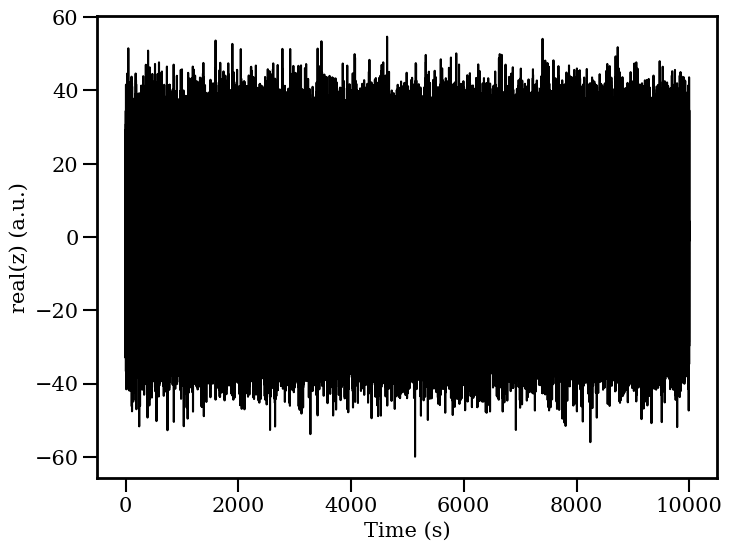

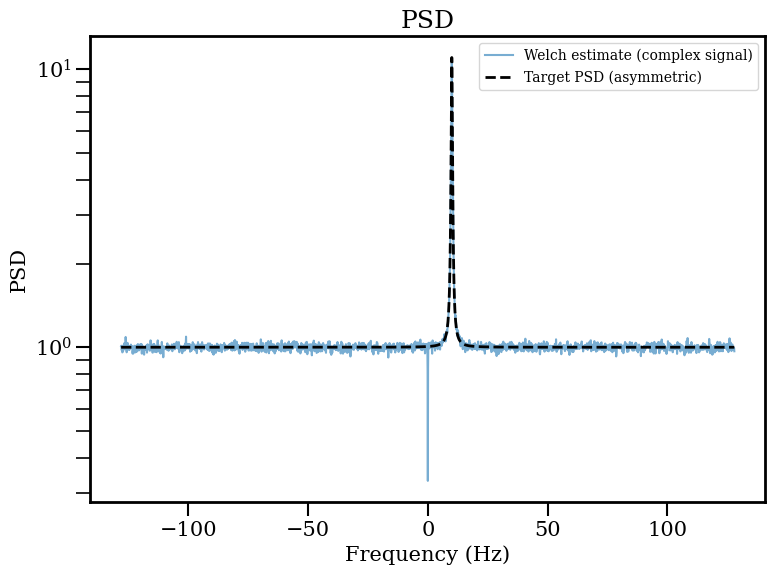

In [5]:
# Genero una time trace di rumore complessa z con una certa forma e una certa durata.

fs = 256        # sampling frequency, Hz
npt = 2560    # numero di punti in una finestra di acquisizione
nev = 1000       # numero di finestre di acquisizione
S0 = 1          # flat noise level
A = 10          # Lorentzian peak amplitude
f0 = 10.0       # Lorentzian center frequency, Hz
fwhm = 0.5      # Lorentzian FWHM, Hz

#============================================
N = npt*nev      # number of samples

psd_func_asym = lambda f: asym_psd(f, S0, A, f0, fwhm)
z_noise = generate_complex_time_series(N, fs, psd_func_asym) #NB, z è lungo N

# calcolo la PSD complessa sul segnale simulato z
f_est2, Pxx_est2 = welch(z_noise, fs=fs, nperseg=npt, return_onesided=False)
order2 = np.argsort(f_est2)
f_est2, Pxx_est2 = f_est2[order2], Pxx_est2[order2]

t_z = np.arange(0,len(z_noise))/fs

plt.plot(t_z,z_noise.real,color="k")
plt.xlabel("Time (s)")
plt.ylabel("real(z) (a.u.)")
plt.show()

plt.semilogy(f_est2, Pxx_est2, alpha=0.6, label="Welch estimate (complex signal)")
plt.semilogy(f_est2, psd_func_asym(f_est2), "k--", lw=2, label="Target PSD (asymmetric)")
plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD")
plt.legend(fontsize=10)
plt.title("PSD")
plt.tight_layout()

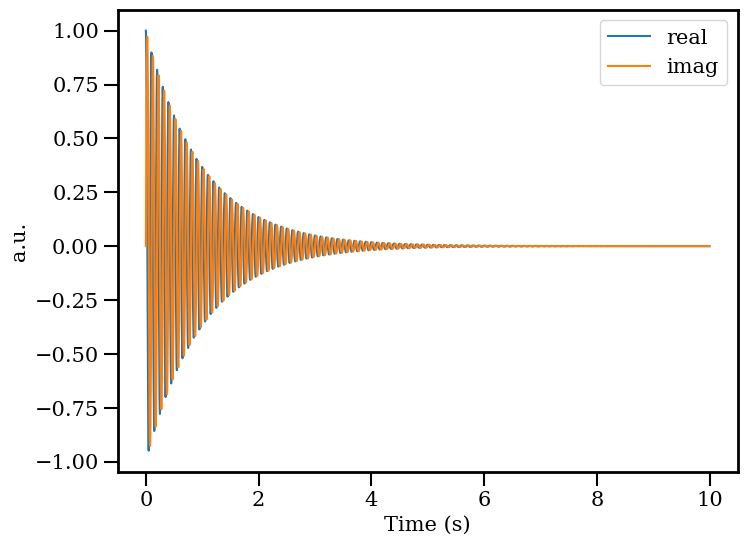

In [6]:
# Definisco la forma del segnale atteso
# NB: t deve essere sufficientemente lungo da contenere tutto il segnale atteso. Conviene farlo lungo tot volte tau
#     In questo esempio, tau è di 1 secondo e il template è lungo 10 s

t = np.arange(0,npt)*1/fs

medium = signal(t,A=1,f0=f0,tau=1,phi=0,t0=0)

plt.plot(t,medium.real,label="real")
plt.plot(t,medium.imag,label="imag")
plt.legend()
plt.xlabel("Time (s)")
plt.ylabel("a.u.")
plt.show()

In [8]:
# Creo il filtro ottimo

# Definisco il Noise Power Spectrum (NPS). 
# NPS deve avere le stesse caratteristiche temporali del template che ho usato per definire il segnale atteso
_ , NPS, _ = filters.PSD(z_noise.reshape(nev,npt),1/fs)

MatchedFilter = filters.OF(medium=medium,NPS=NPS)
MatchedFilter.create_filter(normalization="SNR")


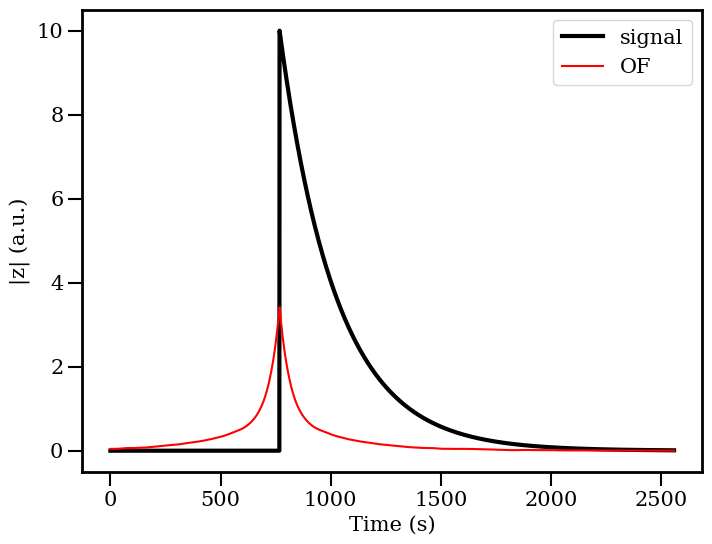

In [11]:
ss = signal(t,A=10,f0=f0,tau=1,phi=0,t0=3)

plt.plot(np.abs(ss),label="signal",lw=3,color="k")
plt.plot(np.abs(MatchedFilter.filter_event(ss)),label="OF",color="r")
plt.legend()
plt.xlabel("Time (s)")
plt.ylabel("|z| (a.u.)")
plt.show()

# Creo dei fake data

In [13]:
# creo un fake data-stream (noise + segnale)

npt_data = 2560*2
A_signal = 50
t0 = 5 # s
#======================================

t_data = np.arange(0,npt_data)*1/fs
fake_signal = signal(t_data,A=A_signal,f0=f0,tau=1,phi=0,t0=t0)

fake_data = generate_complex_time_series(npt_data, fs, psd_func_asym) +fake_signal

In [14]:
filtered = MatchedFilter.filter_event(fake_data,domain="time")

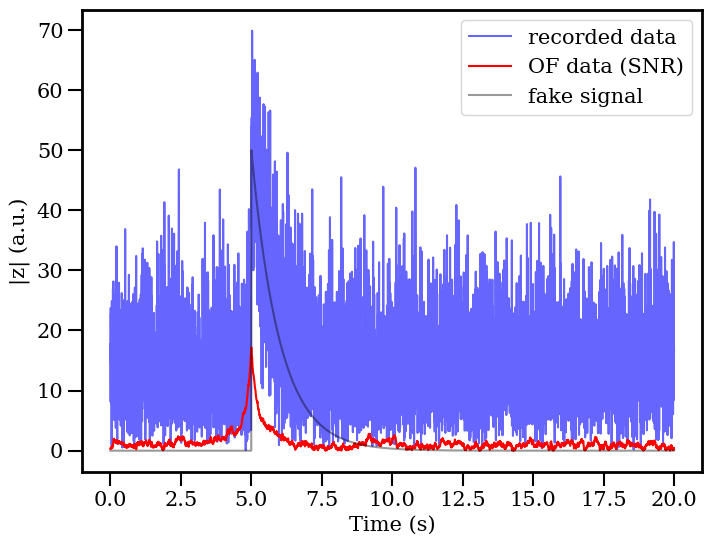

In [15]:
plt.plot(t_data,np.abs(fake_data),color="b",alpha=0.6,label="recorded data")
plt.plot(t_data,np.abs(filtered),color="r",label="OF data (SNR)",alpha=1)
plt.plot(t_data,np.abs(fake_signal),color="k",label="fake signal",alpha=0.4)

plt.legend()
plt.xlabel("Time (s)")
plt.ylabel("|z| (a.u.)")
plt.show()

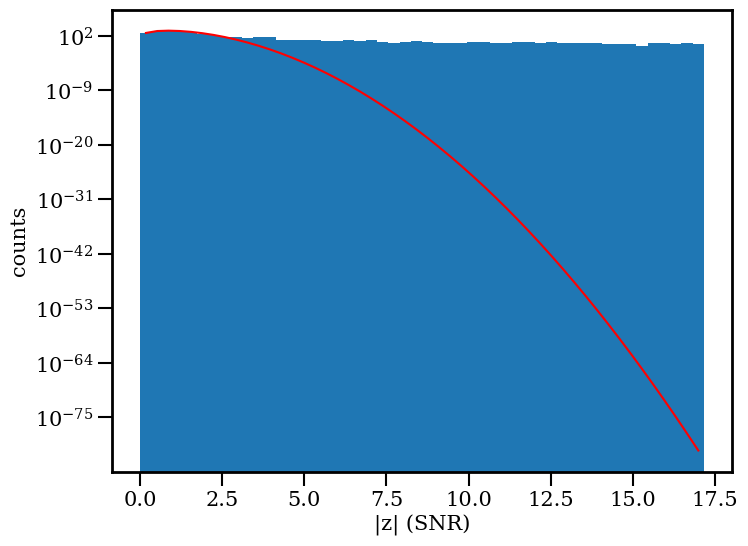

In [17]:
from scipy.optimize import curve_fit

rayleigh = lambda x, s,A: A*(x / s**2) * np.exp(-x**2 / (2 * s**2))

     
counts, edges = np.histogram(np.abs(filtered), bins=50, density=False)
centers = 0.5 * (edges[:-1] + edges[1:])
param, cov = curve_fit(rayleigh, centers, counts, p0=[np.std(np.abs(filtered)),np.sum(counts)*(edges[1]-edges[0])])
        


plt.hist(np.abs(filtered),bins=50)
plt.yscale("log")

plt.plot(centers,rayleigh(centers,*param),color="r")
plt.xlabel("|z| (SNR)")
plt.ylabel("counts")

plt.show()

# Plot single event

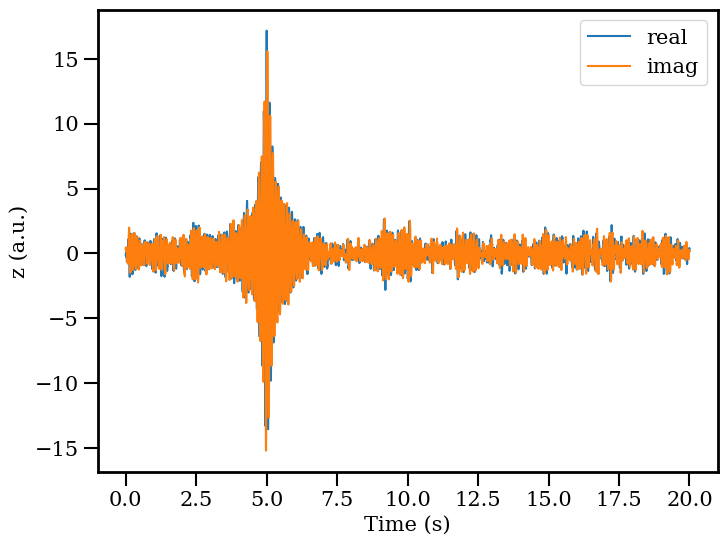

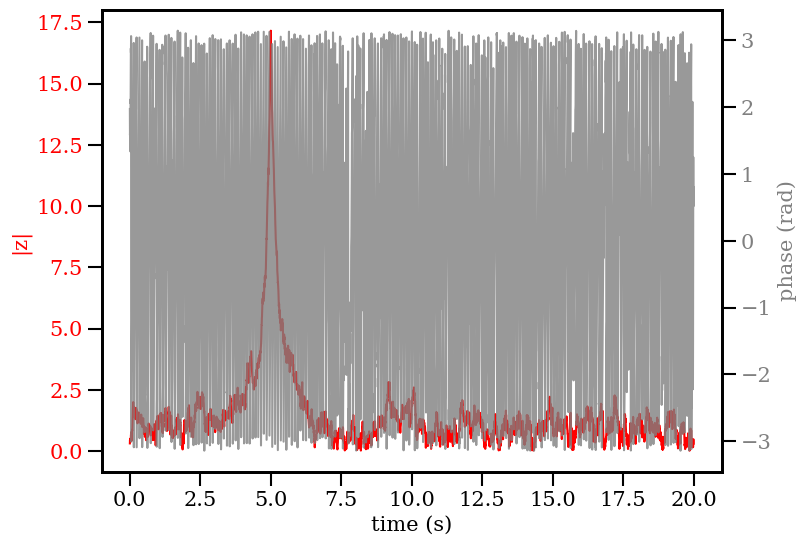

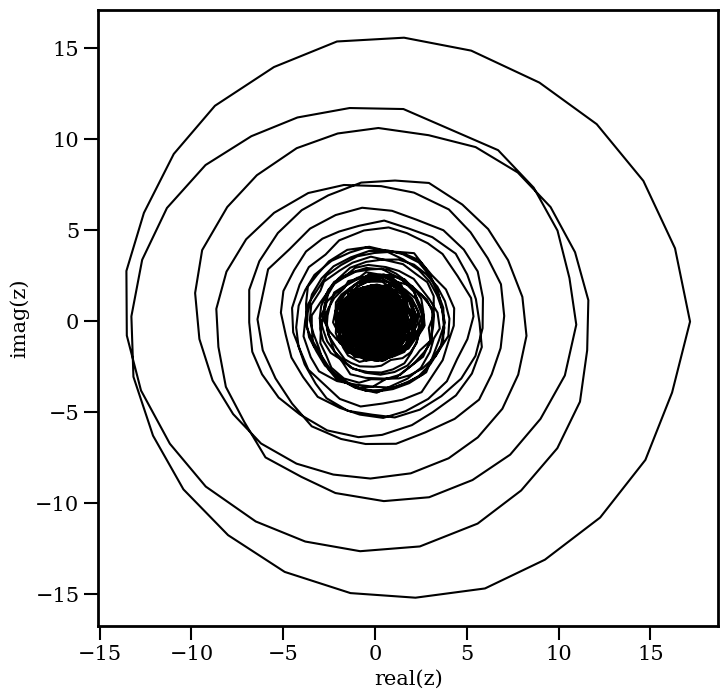

In [18]:
DATA = filtered
x_DATA = t_data
#======================
plt.plot(x_DATA,DATA.real,label="real")
plt.plot(x_DATA,DATA.imag,label="imag")
plt.legend()
plt.xlabel("Time (s)")
plt.ylabel("z (a.u.)")
plt.show()


fig, ax1 = plt.subplots()
color = 'r'
ax1.set_xlabel('time (s)')
ax1.set_ylabel('|z|', color=color)
ax1.plot(x_DATA, np.abs(DATA), color=color)
ax1.tick_params(axis='y', labelcolor=color)
ax2 = ax1.twinx()  
color = 'grey'
ax2.set_ylabel('phase (rad)', color=color) 
ax2.plot(x_DATA, np.angle(DATA), color=color,alpha=0.8)
ax2.tick_params(axis='y', labelcolor=color)
plt.show()

rc('figure', figsize=(8,8))
plt.plot(np.real(DATA),np.imag(DATA),"-",color="k")
plt.xlabel("real(z)")
plt.ylabel("imag(z)")
plt.show()
rc('figure', figsize=(8,6))
